## PCA로 특성을 요약하고 시각화하기

In [1]:
import numpy as np
import pandas as pd
import plotly.express as px
from IPython.display import display
from sklearn.datasets import load_wine
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

px.defaults.template = "plotly_white"


### PCA를 왜 사용할까

특성의 수를 차원이라고 한다. 특성이 많으면 데이터의 분포를 한눈에 보기 어렵고, 모델에 넣을 입력도 많아진다.
PCA(Principal Component Analysis, 주성분 분석)는 여러 특성에 담긴 주요 변동을 더 적은 수의 좌표로 요약하는 차원 축소 방법이다.
줄인 좌표는 데이터를 시각화하거나 다른 모델의 입력으로 사용할 수 있다.

### PCA는 어떤 원리로 동작할까

PCA는 여러 특성을 조합해 새로운 축을 만든다. 데이터가 가장 넓게 퍼지는 방향부터 축을 정하고, 필요한 개수만 남긴다.
이때 퍼진 정도를 분산으로 측정하며, 새로 찾은 축을 주성분 축이라고 한다.

각 점을 새 축 위의 좌표로 나타내는 것을 투영이라고 한다. 특성이 두 개인 데이터를 축 하나에 투영하면, 각 표본을 좌표 하나로 표현할 수 있다.
PCA는 정답 없이 입력 데이터에서 축을 찾으므로 비지도학습에 해당한다.


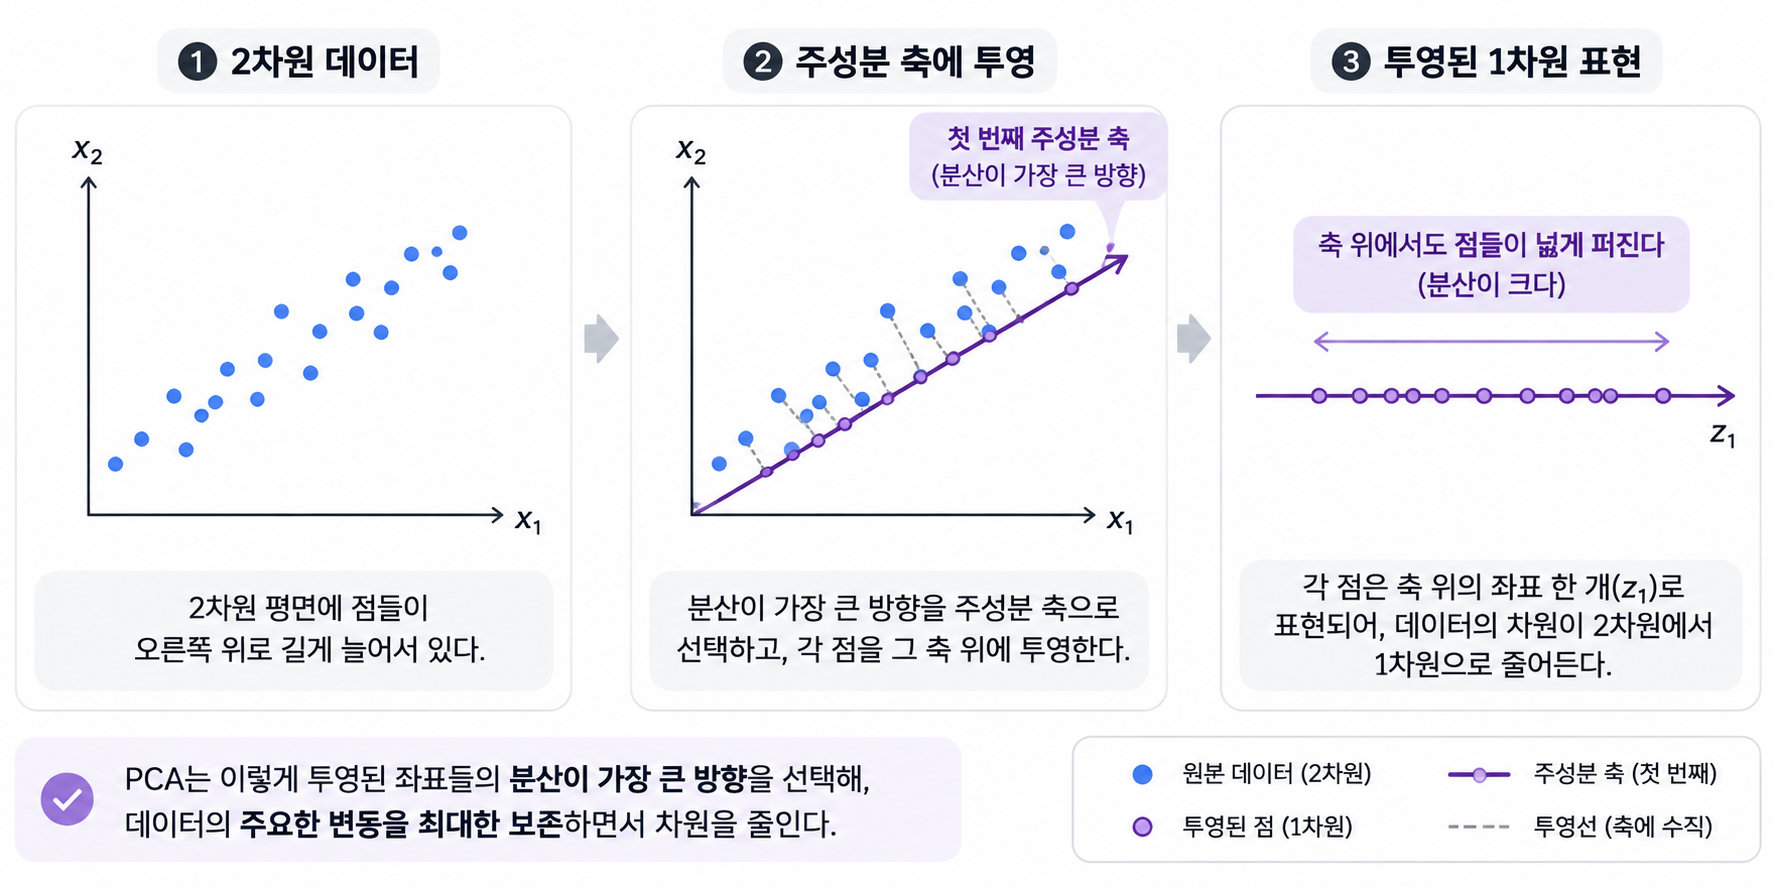

## 와인 측정값 요약하기

### 와인 데이터 불러오기

Wine 데이터에는 와인 178개 표본의 숫자 특성 13개가 있다. 한 행은 와인 한 표본이고, 한 열은 성분이나 색 등의 측정값이다.
13개 측정값에 걸친 표본의 분포를 평면에서 표현하기 위해 PCA로 두 좌표를 만든다.

| 역할 | 항목 | 의미 |
| --- | --- | --- |
| 입력 | `alcohol` | 알코올 함량 |
| 입력 | `color_intensity` | 색 강도 |
| 입력 | `proline` | 아미노산인 프롤린의 측정값 |
| 입력 | 나머지 10개 특성 | 와인의 다른 성분·특성 측정값 |
| 시각화 | `target` | 세 품종을 나타내는 번호 0·1·2 |

입력 `X`는 13개 측정값을 담은 2차원 표다. 품종 정보는 PCA 결과를 색으로 구분하는 데만 사용하고, PCA는 측정값으로 학습한다.


In [2]:
wine = load_wine(as_frame=True)
X = wine.data

print("전체 데이터:", X.shape)
display(X.head())


전체 데이터: (178, 13)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


### 데이터 표준화

전체 Wine 데이터의 분포를 살펴보기 위해 178개 표본을 모두 사용한다. 척도가 다른 측정값을 표준화한다.


In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("표준화한 데이터:", X_scaled.shape)


표준화한 데이터: (178, 13)


### PCA 학습과 변환

`PCA`로 표준화한 13개 측정값을 두 개의 주성분 좌표로 줄인다.


In [4]:
# n_components=2: 주성분 좌표 두 개를 남긴다.
pca_2d = PCA(n_components=2, svd_solver="full")
# 입력 (178, 13) → 주성분 좌표 배열 (178, 2)
X_pca = pca_2d.fit_transform(X_scaled)
print("변환 전·후:", X_scaled.shape, X_pca.shape)


변환 전·후: (178, 13) (178, 2)


### 표준화 전후 PCA 비교

PCA는 분산이 큰 방향을 찾으므로 특성의 척도에 영향을 받는다.
표준화 전후의 점 분포를 비교하며, 척도를 맞추는 것이 PCA 결과를 어떻게 바꾸는지 확인한다.

점 하나는 와인 한 표본이며, PC1·PC2는 원래 13개 특성을 조합해 만든 새로운 축이다.
색을 나타내는 `Cultivar`는 데이터에 원래 들어 있던 품종 정보이며, PCA는 측정값만으로 축을 구한다. 두 그림의 좌표 단위는 서로 다르다.

왼쪽은 표준화 전, 오른쪽은 표준화 후의 결과다. 왼쪽에서는 서로 다른 품종의 점들이 더 많이 겹치고, 오른쪽에서는 품종별 분포가 더 뚜렷하게 나타난다.
이 데이터에서는 표준화 전 변동의 크기가 큰 `proline`이 첫 번째 축에 강하게 반영되었다고 예측할 수 있다.. 표준화 후에는 각 특성의 분산이 같아져 여러 특성의 관계가 축에 반영된다.


In [5]:
raw_pca = PCA(n_components=2, svd_solver="full")
raw_coordinates = raw_pca.fit_transform(X)

comparison_plot = pd.DataFrame(
    np.vstack([raw_coordinates, X_pca]), columns=["PC1", "PC2"],
)
comparison_plot["Scaling"] = ["Without scaling"] * len(X) + ["With scaling"] * len(X)
# 품종 번호를 이름으로 바꾸고, 두 그래프에 같은 표본 순서로 넣는다.
comparison_plot["Cultivar"] = list(wine.target_names[wine.target.to_numpy()]) * 2
# px.scatter: x·y 열로 산점도를 만들고 color 열로 색을 구분한다.
# facet_col: 지정한 열의 값에 따라 그래프를 가로로 나눈다.
comparison_figure = px.scatter(
    comparison_plot, x="PC1", y="PC2", color="Cultivar", facet_col="Scaling",
    opacity=0.8, width=1000, height=450,
)
# matches=None: 표준화 전후의 좌표 단위가 다르므로 각 그래프의 축 범위를 독립적으로 정한다.
comparison_figure.update_xaxes(matches=None)
comparison_figure.update_yaxes(matches=None, showticklabels=True)
comparison_figure.show()


## 남길 차원 수 정하기

### 설명 분산과 누적 비율

설명 분산 비율은 각 주성분이 표준화한 데이터의 전체 분산 중 얼마나 보존하는지를 나타낸다.
이 비율을 더한 누적 비율로, 남긴 축들이 보존하는 변동의 크기를 확인한다. 누적 비율이 90%라면 표준화한 데이터 분산의 90%를 보존한 것이다.


In [6]:
# n_components를 생략하면 이 데이터의 주성분 13개를 모두 구한다.
full_pca = PCA(svd_solver="full").fit(X_scaled)

# explained_variance_ratio_: 주성분별 설명 분산 비율 배열 (13,), cumsum: 누적 합
variance_table = pd.DataFrame({
    "components": np.arange(1, X.shape[1] + 1),
    "variance_ratio": full_pca.explained_variance_ratio_,
    "cumulative_ratio": np.cumsum(full_pca.explained_variance_ratio_),
})
display(variance_table)
# px.line: x·y 열의 값을 선으로 연결한다. markers=True는 각 관측 위치에 점을 표시한다.
variance_figure = px.line(
    variance_table, x="components", y="cumulative_ratio", markers=True,
    labels={"components": "Number of components", "cumulative_ratio": "Cumulative explained variance"},
    width=700, height=450,
)
# add_hline: y에 지정한 높이에 수평 기준선을 추가한다.
variance_figure.add_hline(y=0.9, line_dash="dash", line_color="gray", annotation_text="90%")
variance_figure.show()
print("두 축의 설명 분산 비율 합:", pca_2d.explained_variance_ratio_.sum())


,components,variance_ratio,cumulative_ratio
0,1,0.361988,0.361988
1,2,0.192075,0.554063
2,3,0.111236,0.665300
3,4,0.070690,0.735990
4,5,0.065633,0.801623
5,6,0.049358,0.850981
6,7,0.042387,0.893368
7,8,0.026807,0.920175
8,9,0.022222,0.942397
9,10,0.019300,0.961697


두 축의 설명 분산 비율 합: 0.554063383569353


### 보존할 분산 비율로 차원 수 정하기

보존할 분산 비율을 지정하면 PCA가 필요한 차원 수를 정한다.
표준화한 데이터 분산의 90%를 넘게 보존하도록 차원을 줄인다.


In [10]:
# n_components에 0~1 사이 실수를 넣으면 해당 분산 비율을 넘는 최소 차원 수를 선택한다.
selected_pca = PCA(n_components=0.9, svd_solver="full")
selected_coordinates = selected_pca.fit_transform(X_scaled)

print("선택한 차원 수:", selected_pca.n_components_)
print("누적 설명 분산 비율:", selected_pca.explained_variance_ratio_.sum())
print("변환 후 좌표:", selected_coordinates.shape)


선택한 차원 수: 8
누적 설명 분산 비율: 0.9201754434577264
변환 후 좌표: (178, 8)
